# Статистика для ML — домашнее задание

**Автор:** _имя_ · **Модуль:** математика для ML, тема 4

Как устроено каждое задание:

1. **Ожидание** — гипотеза или ожидаемый результат до расчётов.
2. **Расчёт** — код на NumPy / SciPy, таблицы и графики.
3. **Вывод** — 2–4 предложения своими словами: подтвердилось ли ожидание и почему.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # генератор случайных чисел; 42 — чтобы результаты повторялись
pd.set_option("display.precision", 3)

## 0. Функции

Функции, которые используются в нескольких заданиях.

In [12]:
# функции появятся по ходу заданий
def describe(x):
    """Описательные статистики выборки; пригодится и в задании 8."""
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # границы «усов» box plot
    return pd.Series({
        "среднее": np.mean(x),
        "медиана": np.median(x),
        "мода (округл.)": stats.mode(np.round(x), keepdims=False).mode,
        "дисперсия": np.var(x, ddof=1),
        "std": np.std(x, ddof=1),
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "выбросов по 1.5·IQR": int(np.sum((x < low) | (x > high))),
    })

def sample_estimates(pop, n, reps=500):
    """reps случайных выборок размера n: для каждой x̄ и дисперсия с ddof=0 и ddof=1."""
    rows = []
    for _ in range(reps):
        s = rng.choice(pop, size=n, replace=False)     # выборка без повторов
        rows.append({"mean": s.mean(), "var0": s.var(ddof=0), "var1": s.var(ddof=1)})
    return pd.DataFrame(rows)

def se(x):
    """Стандартная ошибка среднего по одной выборке: s / √n."""
    return np.std(x, ddof=1) / np.sqrt(len(x))

def ci_z(x, sigma, conf=0.95):
    """ДИ для среднего при известной σ."""
    z = stats.norm.ppf((1 + conf) / 2)                 # 1.96 для 95%
    h = z * sigma / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h

def ci_t(x, conf=0.95):
    """ДИ для среднего при неизвестной σ (Стьюдент)."""
    t = stats.t.ppf((1 + conf) / 2, df=len(x) - 1)     # 2.09 для n = 20
    h = t * se(x)
    return x.mean() - h, x.mean() + h

def ci_boot(x, stat=np.mean, B=1000, conf=0.95):
    """Bootstrap-ДИ для любой статистики (np.mean, np.median, ...)."""
    idx = rng.integers(0, len(x), size=(B, len(x)))    # B пересэмплов с повторами
    boots = stat(x[idx], axis=1)                       # статистика каждого пересэмпла
    a = (1 - conf) / 2
    lo, hi = np.quantile(boots, [a, 1 - a])
    return lo, hi

def binom_vs_poisson(n, p, kmax):
    """Точные биномиальные вероятности и приближение Пуассона для k = 0..kmax."""
    k = np.arange(kmax + 1)
    return pd.DataFrame({"бином": stats.binom.pmf(k, n, p),
                         "Пуассон": stats.poisson.pmf(k, n * p)}, index=pd.Index(k, name="k"))

def max_err(n, p):
    """Максимальная разница вероятностей бинома и Пуассона по всем k."""
    k = np.arange(n + 1)
    return np.max(np.abs(stats.binom.pmf(k, n, p) - stats.poisson.pmf(k, n * p)))

def zscore(x):
    """Стандартизация: сколько s от среднего."""
    return (x - x.mean()) / x.std(ddof=1)

def shapiro_reject_rate(gen, n, reps=300):
    """Как часто Шапиро — Уилк даёт p < 0.05 на выборках размера n из генератора gen."""
    return np.mean([stats.shapiro(gen(n)).pvalue < 0.05 for _ in range(reps)])
def cohens_d(a, b):
    """Размер эффекта: (x̄_b − x̄_a) / общий std двух групп."""
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (b.mean() - a.mean()) / sp

def type1_rate(n_a, n_b, sd_a, sd_b, equal_var, reps=2000):
    """reps A/A-тестов (средние одинаковые): доля p < 0.05 = частота ошибки I рода."""
    a = rng.normal(200, sd_a, (reps, n_a))
    b = rng.normal(200, sd_b, (reps, n_b))
    p = stats.ttest_ind(b, a, axis=1, equal_var=equal_var).pvalue    # 2000 тестов разом
    return np.mean(p < 0.05), p

def corrs(x, y):
    """Ковариация, корреляция Пирсона и Спирмена."""
    return {"cov": np.cov(x, y)[0, 1],
            "Pearson": stats.pearsonr(x, y).statistic,
            "Spearman": stats.spearmanr(x, y).statistic}

from itertools import combinations       # все пары: (v1, v2), (v1, v3), (v2, v3)

def check_assumptions(groups):
    """Таблица n / среднее / std / Shapiro p по группам + p-value Levene."""
    rows = {name: {"n": len(g), "среднее": g.mean(), "std": g.std(ddof=1),
                   "Shapiro p": stats.shapiro(g).pvalue} for name, g in groups.items()}
    return pd.DataFrame(rows).T, stats.levene(*groups.values()).pvalue

def pairwise_mw(groups):
    """Попарные тесты Манна — Уитни (ранговый t-тест) с поправкой Бонферрони."""
    pairs = list(combinations(groups, 2))
    rows = []
    for a, b in pairs:
        p = stats.mannwhitneyu(groups[a], groups[b]).pvalue
        rows.append({"пара": f"{a} vs {b}", "p": p, "p × число пар (Бонферрони)": min(1, p * len(pairs))})
    return pd.DataFrame(rows).set_index("пара")
def prop_ci(k, n, conf=0.95):
    """Доля k/n и её 95% ДИ: p ± 1.96·√(p(1−p)/n)."""
    p = k / n
    h = stats.norm.ppf((1 + conf) / 2) * np.sqrt(p * (1 - p) / n)
    return p, p - h, p + h

def cramers_v(table):
    """Сила связи двух категориальных признаков по таблице сопряжённости (0…1)."""
    chi2 = stats.chi2_contingency(table).statistic
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

## 1. Описательная статистика и выбросы

Выборка из нормального распределения размером 1 000.

- посчитай среднее, медиану, моду, дисперсию, стандартное отклонение и квартили
- вычисли межквартильный размах IQR
- добавь 10 сильных выбросов и пересчитай показатели
- сравни, как изменились среднее, медиана, стандартное отклонение и IQR
- построй гистограмму, box plot и violin plot до и после добавления выбросов
- объясни, какие показатели устойчивы к выбросам

Данные: время ответа сервера ~ N(μ = 200 мс, σ = 20), n = 1000.

До выбросов ожидаю:
  среднее ≈ медиана ≈ мода ≈ 200 (нормальное распределение симметрично)
  std ≈ 20, дисперсия ≈ 400
  Q1 ≈ 200 − 0.674·20 ≈ 186.5,  Q3 ≈ 213.5,  IQR ≈ 1.35·σ ≈ 27
  (0.674σ — у нормального распределения 25% значений ниже μ − 0.674σ)

Добавляю 10 таймаутов по 1000–2000 мс (это ≈1% данных):
  среднее: сдвиг ≈ 10·(1500 − 200) / 1010 ≈ +13 → ≈ 213
  std: вырастет в разы, потому что большие отклонения возводятся в квадрат
  медиана и IQR: почти не изменятся, 10 точек сдвигают середину ряда всего на 5 позиций

Формулы:
  среднее        x̄ = Σxᵢ / n
  дисперсия      s² = Σ(xᵢ − x̄)² / (n − 1),   std s = √s²   (почему n − 1 — в задании 2)
  медиана        середина отсортированного ряда;  Q1, Q3 — точки 25% и 75%
  IQR = Q3 − Q1;  выброс, если x < Q1 − 1.5·IQR  или  x > Q3 + 1.5·IQR
Мини-пример: [1, 2, 3, 4, 100] → среднее 22, медиана 3

                         до     после  изменение  изменение, %
среднее              199.42    211.37      11.95          5.99
медиана              200.12    200.25       0.12          0.06
мода (округл.)       205.00    205.00       0.00          0.00
дисперсия            391.42  15256.35   14864.93       3797.69
std                   19.78    123.52     103.73        524.31
Q1                   186.07    186.27       0.20          0.11
Q3                   211.80    212.51       0.71          0.34
IQR                   25.72     26.24       0.52          2.00
выбросов по 1.5·IQR    9.00     18.00       9.00        100.00


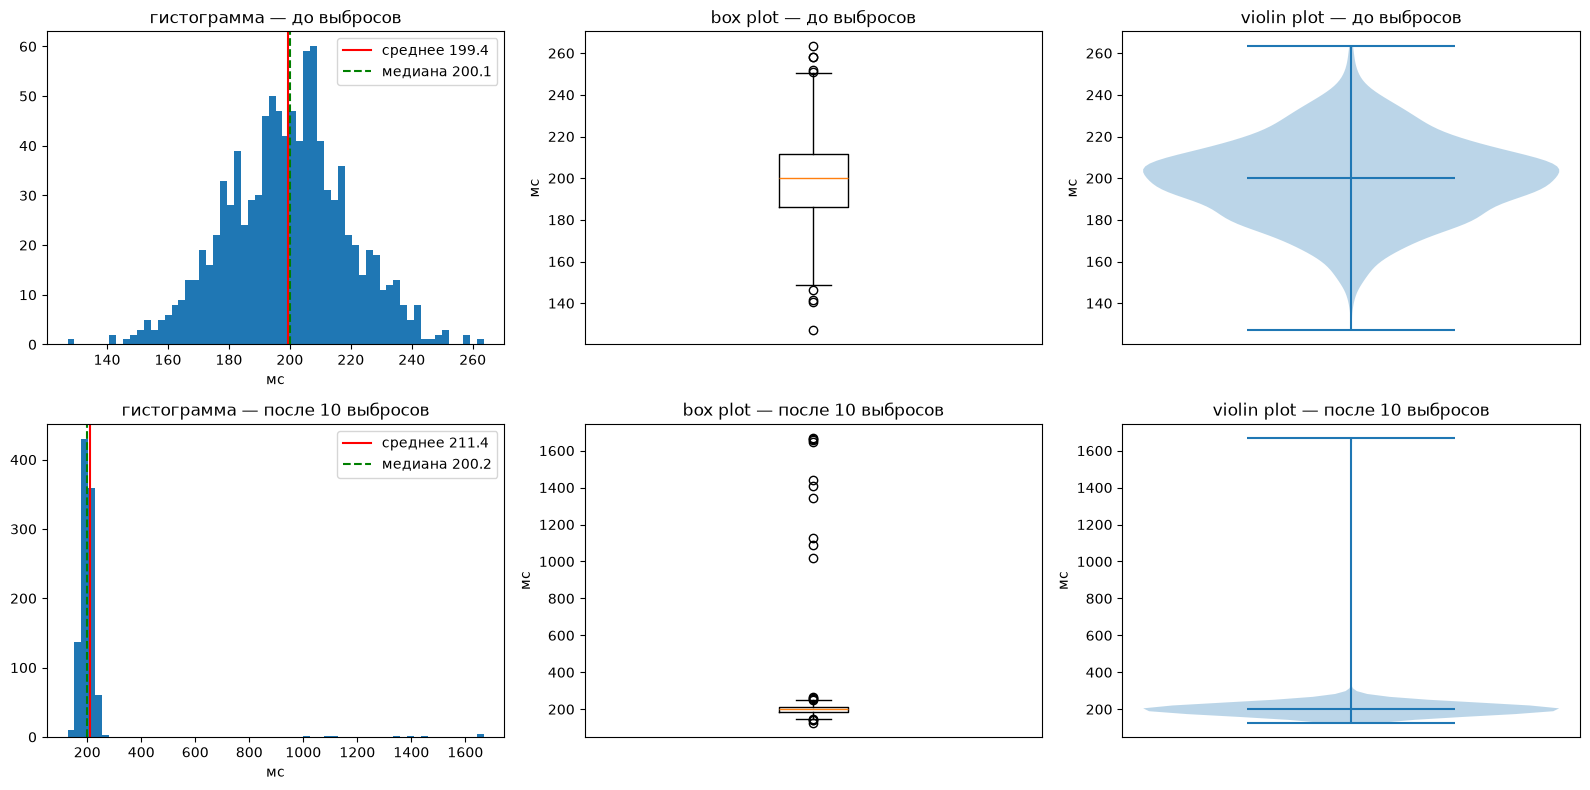

In [5]:
x = rng.normal(200, 20, 1000)                    # время ответа, мс
outliers = rng.uniform(1000, 2000, 10)           # 10 таймаутов
x_out = np.concatenate([x, outliers])

table = pd.DataFrame({"до": describe(x), "после": describe(x_out)})
table["изменение"] = table["после"] - table["до"]
table["изменение, %"] = 100 * table["изменение"] / table["до"]
print(table.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, (data, name) in enumerate([(x, "до выбросов"), (x_out, "после 10 выбросов")]):
    axes[row, 0].hist(data, bins=60)
    axes[row, 0].axvline(np.mean(data), color="red", label=f"среднее {np.mean(data):.1f}")
    axes[row, 0].axvline(np.median(data), color="green", ls="--", label=f"медиана {np.median(data):.1f}")
    axes[row, 0].legend(); axes[row, 0].set_title(f"гистограмма — {name}"); axes[row, 0].set_xlabel("мс")
    axes[row, 1].boxplot(data); axes[row, 1].set_title(f"box plot — {name}")
    axes[row, 2].violinplot(data, showmedians=True); axes[row, 2].set_title(f"violin plot — {name}")
    for ax in axes[row, 1:]:
        ax.set_ylabel("мс"); ax.set_xticks([])
plt.tight_layout(); plt.show()

### 1.1 Ожидание

_Что ожидаю получить до расчётов:_

...

In [ ]:
# задание 1

### 1.2 Вывод

...

## 2. Генеральная совокупность, выборка и оценки

Генеральная совокупность из 100 000 наблюдений с известными средним и дисперсией.

- возьми по 500 случайных выборок размеров 10, 30, 100 и 1 000
- для каждой выборки оцени среднее и дисперсию
- исследуй распределение полученных оценок
- сравни смещение и разброс оценок при разных размерах выборки
- проверь различие между дисперсией с `ddof=0` и `ddof=1`
- объясни понятия несмещённости, состоятельности и стандартной ошибки

### 2.1 Ожидание

_Что ожидаю получить до расчётов:_

...

Генеральная совокупность: 100 000 запросов ~ N(200, 20) → μ ≈ 200, σ² ≈ 400
(точные μ и σ² считаю по всей совокупности с ddof=0: это вся совокупность, а не выборка)

Ожидаю:
1) x̄ несмещённое: среднее x̄ по 500 выборкам ≈ μ при любом n
2) разброс x̄ = SE = σ/√n:   n=10 → 6.3,   30 → 3.7,   100 → 2.0,   1000 → 0.63
   (n в 100 раз больше → точность в 10 раз выше)
3) дисперсия с ddof=0 (делим на n) в среднем занижена: E = σ²·(n−1)/n
   n=10 → 360 (−10%),   30 → 387 (−3%),   100 → 396 (−1%),   1000 → 399.6 (−0.1%)
4) с ddof=1 (делим на n−1) в среднем ≈ σ² при любом n
5) с ростом n все оценки сжимаются к истине — это состоятельность

генеральная совокупность: μ = 199.92, σ² = 403.1, σ = 20.08

                              10      30      100     1000
среднее x̄ по 500 выборкам  199.56  199.61  199.91  199.88
смещение x̄                  -0.36   -0.31   -0.01   -0.04
разброс x̄ (std)              6.64    3.56    2.11    0.67
SE теория σ/√n                6.35    3.67    2.01    0.63
среднее var ddof=0          354.56  391.85  401.29  402.99
теория σ²(n−1)/n            362.77  389.64  399.05  402.68
среднее var ddof=1          393.96  405.37  405.34  403.40
разброс var ddof=1 (std)    191.31  106.72   58.84   18.40

одна выборка n=30: x̄ = 203.66, SE по выборке = 4.03, теория = 3.67


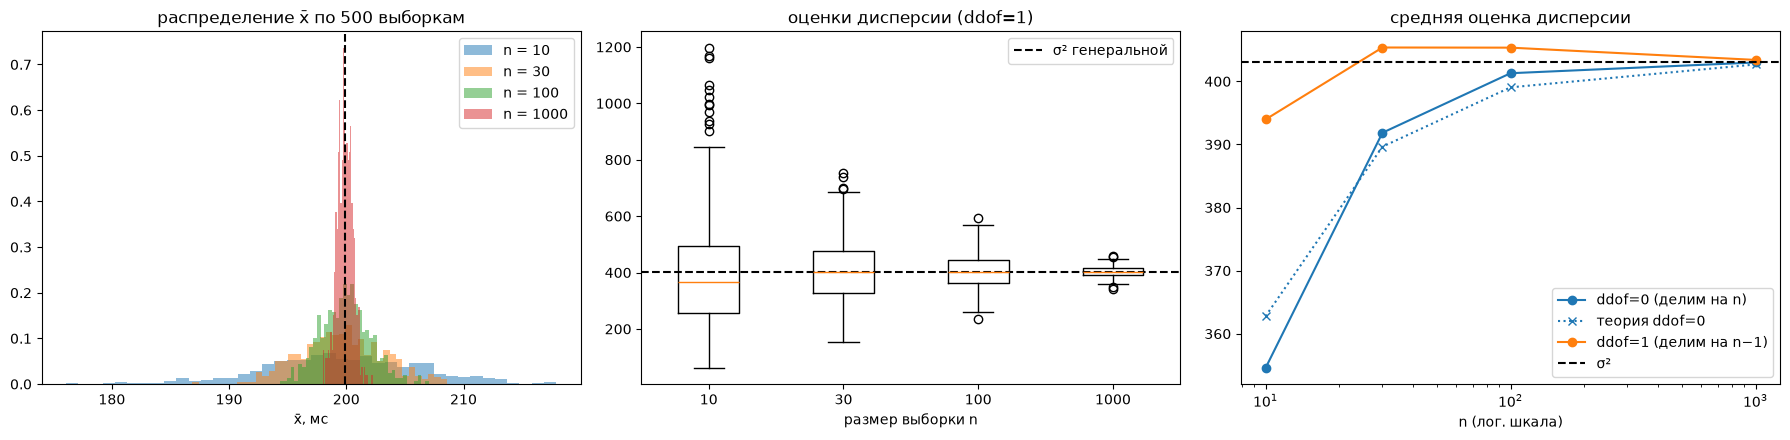

In [7]:
# задание 2
pop = rng.normal(200, 20, 100_000)                     # генеральная совокупность
mu, sigma2 = pop.mean(), pop.var(ddof=0)
print(f"генеральная совокупность: μ = {mu:.2f}, σ² = {sigma2:.1f}, σ = {np.sqrt(sigma2):.2f}\n")

sizes = (10, 30, 100, 1000)
est = {n: sample_estimates(pop, n) for n in sizes}

summary = pd.DataFrame({
    n: {
        "среднее x̄ по 500 выборкам": e["mean"].mean(),
        "смещение x̄": e["mean"].mean() - mu,
        "разброс x̄ (std)": e["mean"].std(),
        "SE теория σ/√n": np.sqrt(sigma2 / n),
        "среднее var ddof=0": e["var0"].mean(),
        "теория σ²(n−1)/n": sigma2 * (n - 1) / n,
        "среднее var ddof=1": e["var1"].mean(),
        "разброс var ddof=1 (std)": e["var1"].std(),
    } for n, e in est.items()
})
print(summary.round(2))

# в жизни выборка одна, поэтому SE оцениваем по ней самой
one = rng.choice(pop, 30, replace=False)
print(f"\nодна выборка n=30: x̄ = {one.mean():.2f}, SE по выборке = {se(one):.2f}, теория = {np.sqrt(sigma2 / 30):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for n in sizes:
    axes[0].hist(est[n]["mean"], bins=40, density=True, alpha=0.5, label=f"n = {n}")
axes[0].axvline(mu, color="black", ls="--"); axes[0].legend()
axes[0].set_title("распределение x̄ по 500 выборкам"); axes[0].set_xlabel("x̄, мс")

axes[1].boxplot([est[n]["var1"] for n in sizes], tick_labels=[str(n) for n in sizes])
axes[1].axhline(sigma2, color="black", ls="--", label="σ² генеральной")
axes[1].set_title("оценки дисперсии (ddof=1)"); axes[1].set_xlabel("размер выборки n"); axes[1].legend()

axes[2].plot(sizes, [est[n]["var0"].mean() for n in sizes], "o-", label="ddof=0 (делим на n)")
axes[2].plot(sizes, [sigma2 * (n - 1) / n for n in sizes], "x:", color="C0", label="теория ddof=0")
axes[2].plot(sizes, [est[n]["var1"].mean() for n in sizes], "o-", label="ddof=1 (делим на n−1)")
axes[2].axhline(sigma2, color="black", ls="--", label="σ²")
axes[2].set_xscale("log"); axes[2].legend()
axes[2].set_title("средняя оценка дисперсии"); axes[2].set_xlabel("n (лог. шкала)")
plt.tight_layout(); plt.show()

### 2.2 Вывод

...

## 3. Доверительные интервалы

- построй 95% доверительный интервал для среднего при известной дисперсии
- повтори расчёт при неизвестной дисперсии с использованием распределения Стьюдента
- сравни ширину интервалов для выборок размеров 20, 100 и 1 000
- реализуй bootstrap-интервал для среднего и медианы
- проведи не менее 1 000 экспериментов и оцени, как часто интервалы действительно содержат параметр генеральной совокупности
- объясни корректный смысл 95% доверительного интервала

### 3.1 Ожидание

_Что ожидаю получить до расчётов:_

...

истина: μ = 199.92, медиана = 199.82, σ = 20.08

                             20              100             1000
x̄                        210.232         198.307         199.901
z-интервал         [201.4; 219.0]  [194.4; 202.2]  [198.7; 201.1]
t-интервал         [202.7; 217.8]  [194.5; 202.2]  [198.7; 201.1]
bootstrap среднее  [202.8; 216.7]  [194.5; 202.0]  [198.7; 201.2]
bootstrap медиана  [205.6; 220.1]  [193.6; 201.8]  [199.2; 202.0]
ширина z                   17.598            7.87           2.489
ширина t                   15.089           7.688           2.482
t-крит.                     2.093           1.984           1.962 

доля интервалов, накрывших истину (цель 0.95):
                   n = 10  n = 50
z (σ известна)      0.939   0.947
t (σ неизвестна)    0.942   0.941
z с s вместо σ      0.901   0.937
bootstrap среднее   0.876   0.935
bootstrap медиана   0.922   0.953


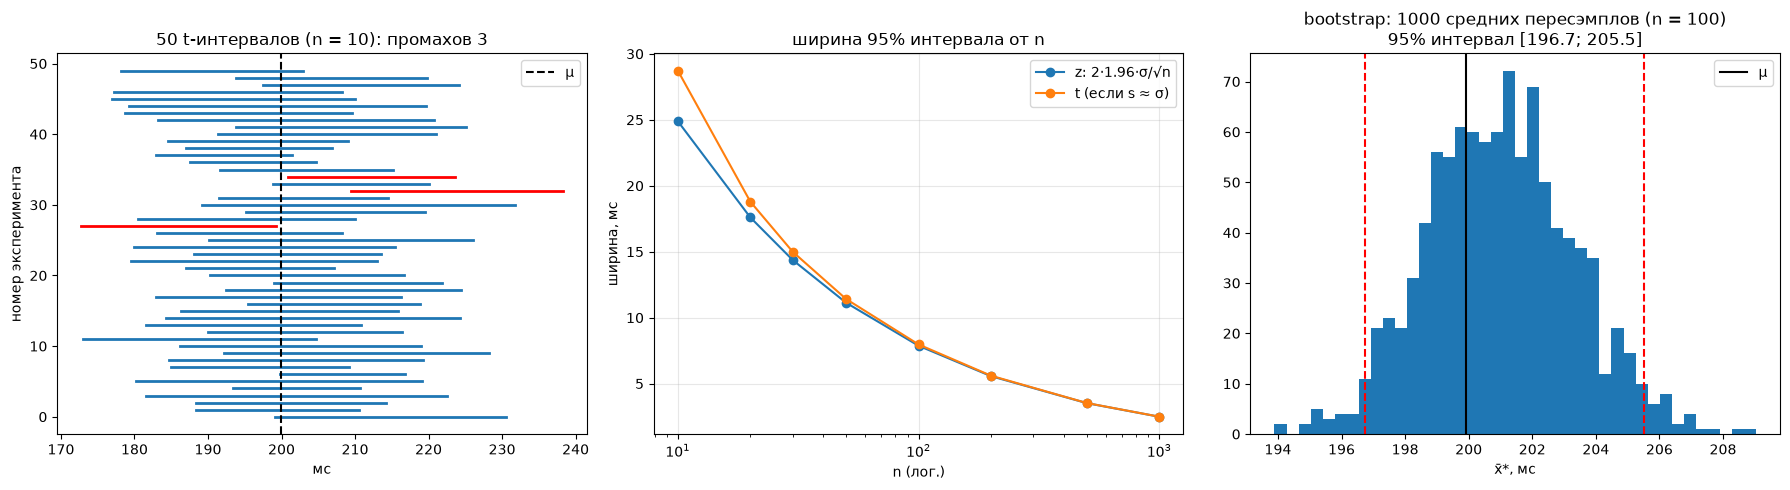

In [9]:
# задание 3
sigma = np.sqrt(sigma2)
med = np.median(pop)
print(f"истина: μ = {mu:.2f}, медиана = {med:.2f}, σ = {sigma:.2f}\n")

# 1) интервалы для одной выборки разных размеров
rows = {}
for n in (20, 100, 1000):
    s = rng.choice(pop, n, replace=False)
    z, t, bm, bmed = ci_z(s, sigma), ci_t(s), ci_boot(s), ci_boot(s, np.median)
    rows[n] = {
        "x̄": s.mean(),
        "z-интервал": f"[{z[0]:.1f}; {z[1]:.1f}]",
        "t-интервал": f"[{t[0]:.1f}; {t[1]:.1f}]",
        "bootstrap среднее": f"[{bm[0]:.1f}; {bm[1]:.1f}]",
        "bootstrap медиана": f"[{bmed[0]:.1f}; {bmed[1]:.1f}]",
        "ширина z": z[1] - z[0],
        "ширина t": t[1] - t[0],
        "t-крит.": stats.t.ppf(0.975, n - 1),
    }
print(pd.DataFrame(rows).to_string(), "\n")

# 2) 1000 экспериментов: как часто интервал накрывает истину
def coverage(n, experiments=1000):
    hits = {"z (σ известна)": 0, "t (σ неизвестна)": 0, "z с s вместо σ": 0,
            "bootstrap среднее": 0, "bootstrap медиана": 0}
    saved = []
    for _ in range(experiments):
        s = rng.choice(pop, n, replace=False)
        z, t = ci_z(s, sigma), ci_t(s)
        zs = (s.mean() - 1.96 * se(s), s.mean() + 1.96 * se(s))   # ошибка: 1.96 вместо t
        bm, bmed = ci_boot(s), ci_boot(s, np.median)
        hits["z (σ известна)"] += z[0] <= mu <= z[1]
        hits["t (σ неизвестна)"] += t[0] <= mu <= t[1]
        hits["z с s вместо σ"] += zs[0] <= mu <= zs[1]
        hits["bootstrap среднее"] += bm[0] <= mu <= bm[1]
        hits["bootstrap медиана"] += bmed[0] <= med <= bmed[1]
        saved.append(t)
    return {k: v / experiments for k, v in hits.items()}, np.array(saved)

cov, saved = {}, {}
for n in (10, 50):
    cov[f"n = {n}"], saved[n] = coverage(n)
print("доля интервалов, накрывших истину (цель 0.95):")
print(pd.DataFrame(cov).round(3))

# 3) графики
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
first = saved[10][:50]
miss = (first[:, 0] > mu) | (first[:, 1] < mu)                # интервал не накрыл μ
for i, (lo, hi) in enumerate(first):
    axes[0].plot([lo, hi], [i, i], color="red" if miss[i] else "tab:blue", lw=2)
axes[0].axvline(mu, color="black", ls="--", label="μ")
axes[0].set_title(f"50 t-интервалов (n = 10): промахов {miss.sum()}")
axes[0].set_xlabel("мс"); axes[0].set_ylabel("номер эксперимента"); axes[0].legend()

ns = np.array([10, 20, 30, 50, 100, 200, 500, 1000])
axes[1].plot(ns, 2 * 1.96 * sigma / np.sqrt(ns), "o-", label="z: 2·1.96·σ/√n")
axes[1].plot(ns, 2 * stats.t.ppf(0.975, ns - 1) * sigma / np.sqrt(ns), "o-", label="t (если s ≈ σ)")
axes[1].set_xscale("log"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("ширина 95% интервала от n"); axes[1].set_xlabel("n (лог.)"); axes[1].set_ylabel("ширина, мс")

s = rng.choice(pop, 100, replace=False)
boots = rng.choice(s, size=(1000, len(s))).mean(axis=1)       # 1000 пересэмплов → 1000 средних
lo, hi = np.quantile(boots, [0.025, 0.975])
axes[2].hist(boots, bins=40)
for v in (lo, hi):
    axes[2].axvline(v, color="red", ls="--")
axes[2].axvline(mu, color="black", label="μ")
axes[2].set_title(f"bootstrap: 1000 средних пересэмплов (n = 100)\n95% интервал [{lo:.1f}; {hi:.1f}]")
axes[2].set_xlabel("x̄*, мс"); axes[2].legend()
plt.tight_layout(); plt.show()

### 3.2 Вывод

...

## 4. Распределения Бернулли, Пуассона и нормальное распределение

- сравни точные биномиальные вероятности с приближением Пуассона для редкого события
- исследуй, как меняется качество приближения при разных n и p
- сгенерируй несколько нормальных выборок с разными параметрами
- стандартизируй их и сравни полученные распределения
- построй Q-Q plot и проверь нормальность критерием Шапиро — Уилка
- объясни, почему статистическая значимость теста нормальности зависит от размера выборки

Редкое событие: 1000 запросов, каждый падает с p = 0.002 (Бернулли)
Число упавших ~ Binomial(1000, 0.002) ≈ Poisson(λ = n·p = 2)

Пуассон: P(k) = λᵏ · e^(−λ) / k!
  P(0) = e^(−2) ≈ 0.1353,   P(1) = 2 · e^(−2) ≈ 0.2707,   P(2) = 2²/2 · e^(−2) ≈ 0.2707
Бином: P(0) = 0.998¹⁰⁰⁰ ≈ 0.1351 — почти то же самое

Ожидаю: приближение хорошее при малом p и плохое при p ≥ 0.1
  (ошибка не больше n·p²:  1000 · 0.002² = 0.004,  а при n = 10, p = 0.2 уже 10 · 0.2² = 0.4)

Стандартизация z = (x − x̄)/s: любые нормальные выборки → N(0, 1)
  экспоненциальная тоже получит среднее 0 и std 1, но останется кривой (асимметрия не изменится)
Q-Q plot: нормальные — точки на прямой, экспоненциальная — изгиб
Shapiro — Уилк (H0: данные нормальные):
  нормальные выборки → p > 0.05, ложная тревога только в ~5% случаев
  «почти нормальные» → при n = 20 тест отличия не заметит, при n = 5000 заметит почти всегда

### 4.1 Ожидание

_Что ожидаю получить до расчётов:_

...

число ошибок из 1000 запросов, p = 0.002, λ = 2
   бином  Пуассон  симуляция Бернулли  бином − Пуассон
k                                                     
0 0.1351   0.1353              0.1334          -0.0003
1 0.2707   0.2707              0.2752          -0.0000
2 0.2709   0.2707              0.2820           0.0003
3 0.1806   0.1804              0.1734           0.0002
4 0.0902   0.0902              0.0886          -0.0000
5 0.0360   0.0361              0.0330          -0.0001
6 0.0120   0.0120              0.0102          -0.0001
7 0.0034   0.0034              0.0024          -0.0000
8 0.0008   0.0009              0.0010          -0.0000 

макс. разница вероятностей бинома и Пуассона, п.п.:
          p = 0.5  p = 0.1  p = 0.01  p = 0.001
n = 10      7.063    1.954     0.087      0.001
n = 50      3.275    0.946     0.229      0.005
n = 100     2.326    0.676     0.185      0.009
n = 1000    0.739    0.216     0.063      0.018 

                   среднее      std  среднее z  std

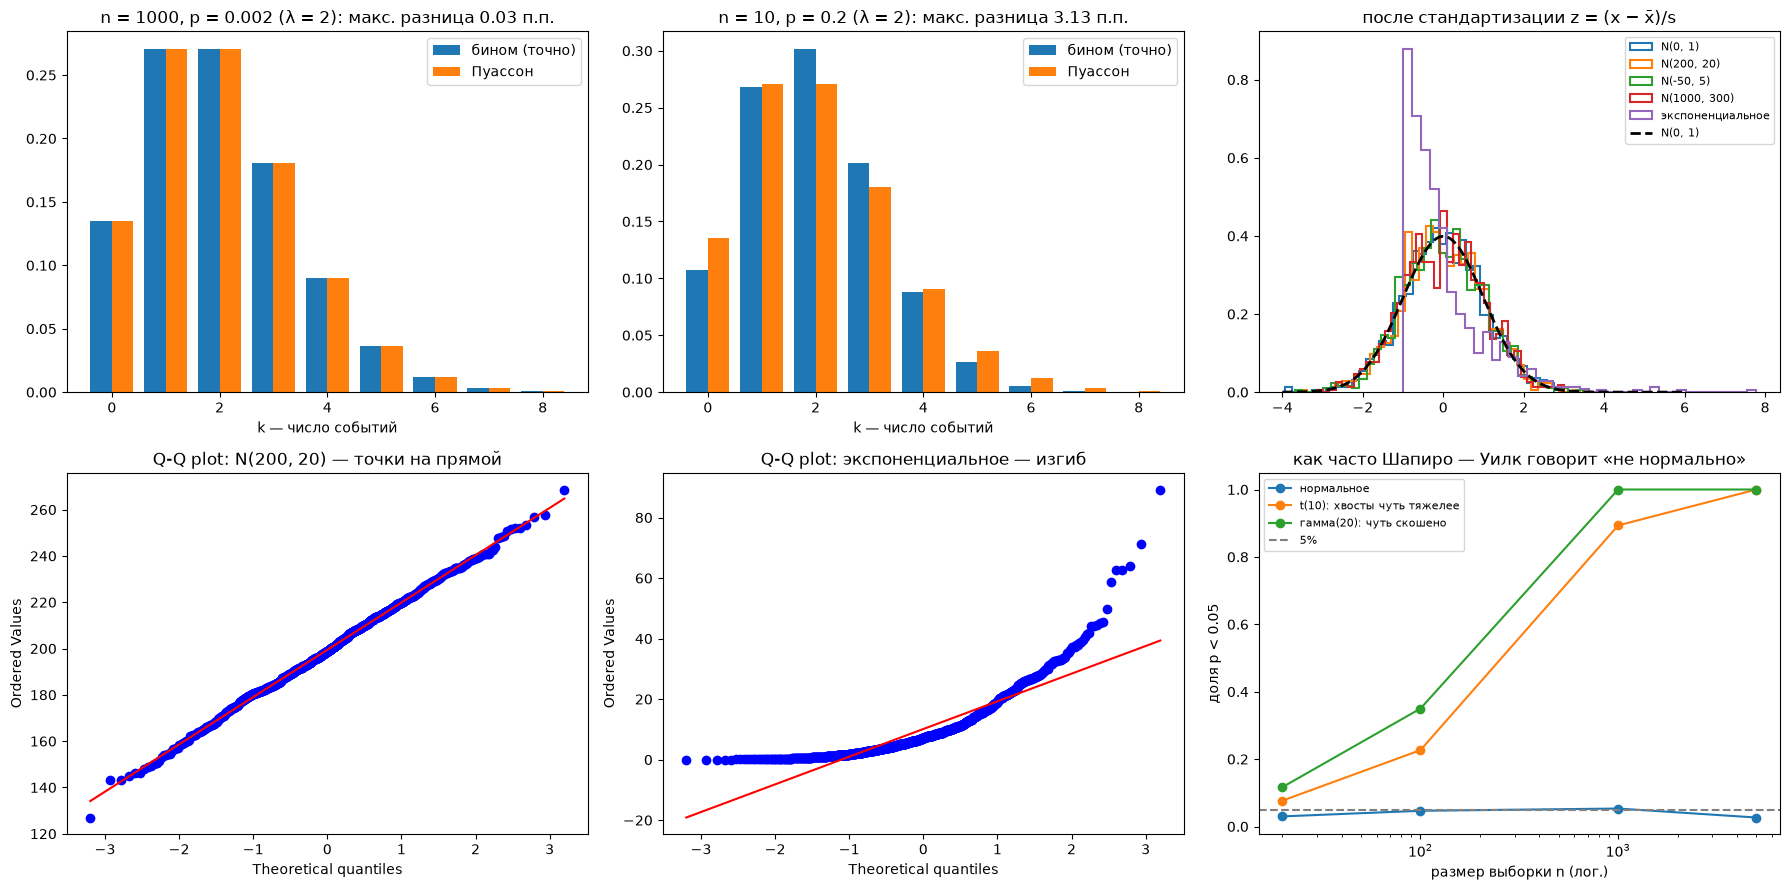

In [11]:
fmt = lambda v: f"{v:.4f}"

# 1) бином против Пуассона для редкого события + симуляция через Бернулли
n, p = 1000, 0.002
tab = binom_vs_poisson(n, p, kmax=8)
sim = (rng.random((5000, n)) < p).sum(axis=1)        # 5000 раз по 1000 испытаний Бернулли
tab["симуляция Бернулли"] = np.bincount(sim, minlength=9)[:9] / len(sim)
tab["бином − Пуассон"] = tab["бином"] - tab["Пуассон"]
print(f"число ошибок из {n} запросов, p = {p}, λ = {n * p:g}")
print(tab.to_string(float_format=fmt), "\n")

# 2) качество приближения при разных n и p
ns, ps = (10, 50, 100, 1000), (0.5, 0.1, 0.01, 0.001)
grid = pd.DataFrame({f"p = {p}": [100 * max_err(n, p) for n in ns] for p in ps},
                    index=[f"n = {n}" for n in ns])
print("макс. разница вероятностей бинома и Пуассона, п.п.:")
print(grid.round(3), "\n")

# 3) нормальные выборки с разными параметрами + одна ненормальная → стандартизация
params = [(0, 1), (200, 20), (-50, 5), (1000, 300)]
samples = {f"N({m}, {s})": rng.normal(m, s, 1000) for m, s in params}
samples["экспоненциальное"] = rng.exponential(10, 1000)
rows = {}
for name, x in samples.items():
    z = zscore(x)
    rows[name] = {"среднее": x.mean(), "std": x.std(ddof=1),
                  "среднее z": z.mean(), "std z": z.std(ddof=1),
                  "асимметрия": stats.skew(x), "Shapiro p": stats.shapiro(x).pvalue}
print(pd.DataFrame(rows).T.round(3), "\n")

# 4) как результат Шапиро — Уилка зависит от n
gens = {"нормальное": lambda n: rng.normal(0, 1, n),
        "t(10): хвосты чуть тяжелее": lambda n: rng.standard_t(10, n),
        "гамма(20): чуть скошено": lambda n: rng.gamma(20, 1, n)}
sizes = (20, 100, 1000, 5000)
rr = pd.DataFrame({name: [shapiro_reject_rate(g, n) for n in sizes] for name, g in gens.items()},
                  index=sizes)
rr.index.name = "n"
print("доля тестов Шапиро — Уилка с p < 0.05 (из 300):")
print(rr.round(3))

# графики
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (n_, p_) in zip(axes[0, :2], [(1000, 0.002), (10, 0.2)]):      # одинаковое λ = 2
    t_ = binom_vs_poisson(n_, p_, kmax=8)
    ax.bar(t_.index - 0.2, t_["бином"], 0.4, label="бином (точно)")
    ax.bar(t_.index + 0.2, t_["Пуассон"], 0.4, label="Пуассон")
    ax.set_title(f"n = {n_}, p = {p_} (λ = 2): макс. разница {100 * max_err(n_, p_):.2f} п.п.")
    ax.set_xlabel("k — число событий"); ax.legend()

grid_z = np.linspace(-4, 6, 300)
for name, x in samples.items():
    axes[0, 2].hist(zscore(x), bins=40, density=True, histtype="step", lw=1.5, label=name)
axes[0, 2].plot(grid_z, stats.norm.pdf(grid_z), "k--", lw=2, label="N(0, 1)")
axes[0, 2].set_title("после стандартизации z = (x − x̄)/s"); axes[0, 2].legend(fontsize=8)

stats.probplot(samples["N(200, 20)"], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q plot: N(200, 20) — точки на прямой")
stats.probplot(samples["экспоненциальное"], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot: экспоненциальное — изгиб")

for col in rr.columns:
    axes[1, 2].plot(rr.index, rr[col], "o-", label=col)
axes[1, 2].axhline(0.05, color="gray", ls="--", label="5%")
axes[1, 2].set_xscale("log"); axes[1, 2].legend(fontsize=8)
axes[1, 2].set_title("как часто Шапиро — Уилк говорит «не нормально»")
axes[1, 2].set_xlabel("размер выборки n (лог.)"); axes[1, 2].set_ylabel("доля p < 0.05")
plt.tight_layout(); plt.show()

In [ ]:
# задание 4

### 4.2 Вывод

...

## 5. Проверка статистических гипотез

Две группы наблюдений, которые имитируют контрольную и экспериментальную группы.

- сформулируй нулевую и альтернативную гипотезы
- сравни средние с помощью t-теста
- проверь равенство дисперсий и выбери подходящий вариант теста
- вычисли p-value и доверительный интервал разницы средних
- оцени размер эффекта через Cohen's d
- повтори эксперимент при отсутствии реального эффекта и оцени частоту ошибки первого рода
- объясни разницу между статистической и практической значимостью

### 5.1 Ожидание

_Что ожидаю получить до расчётов:_

...

Сценарий: A/B-тест кэша
  контроль — старая версия:   N(200, 20), n = 100
  эксперимент — с кэшем:      N(190, 30), n = 100 (быстрее, но разброс больше)

H0: μ_эксп = μ_контр  (кэш не влияет на время ответа)
H1: μ_эксп ≠ μ_контр  (влияет в любую сторону) — двусторонний тест, α = 0.05

Ожидаю:
  разница ≈ −10 мс,  SE разницы = √(20²/100 + 30²/100) = √13 ≈ 3.6
  t ≈ −10 / 3.6 ≈ −2.8  →  p ≈ 0.006 < 0.05  →  отвергаем H0
  95% ДИ разницы ≈ −10 ± 2·3.6 ≈ [−17; −3]
  Levene покажет разные дисперсии → тест Уэлча
  Cohen's d = −10 / √((20² + 30²)/2) ≈ −0.39 → эффект малый-средний

A/A-тест (эффекта нет): p < 0.05 примерно в 5% случаев — это и есть α
При разных σ и разных n Стьюдент будет ошибаться чаще 5%, Уэлч — нет
200 000 против 200 000 с разницей 0.5 мс: p крошечный, но d ≈ 0.025 → значимо, но бесполезно

         контроль  эксперимент
среднее    198.99       189.68
std         15.53        29.39
n          100.00       100.00 

Levene: p = 0.0000 → дисперсии различаются → t-тест Уэлча
разница средних = -9.31 мс
t = -2.80, p-value = 0.0057, 95% ДИ разницы = [-15.88; -2.75]
(для сравнения Стьюдент: p = 0.0056)
Cohen's d = -0.40

доля p < 0.05, когда эффекта НЕТ (цель 0.05):
равные σ и n: Стьюдент    0.052
равные σ и n: Уэлч        0.043
разные σ и n: Стьюдент    0.263
разные σ и n: Уэлч        0.050
dtype: float64 

200 000 vs 200 000, разница -0.55 мс: p = 2.1e-18, ДИ [-0.68; -0.43], d = -0.028


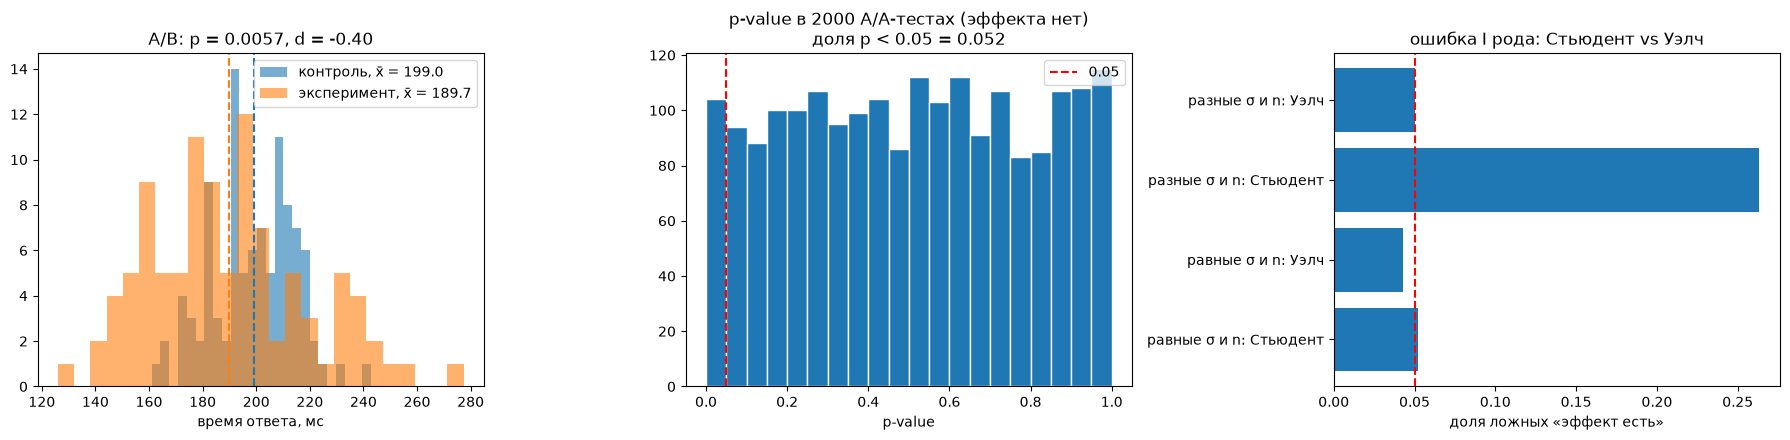

In [5]:
# задание 5
control = rng.normal(200, 20, 100)
treat = rng.normal(190, 30, 100)
print(pd.DataFrame({"контроль": [control.mean(), control.std(ddof=1), len(control)],
                    "эксперимент": [treat.mean(), treat.std(ddof=1), len(treat)]},
                   index=["среднее", "std", "n"]).round(2), "\n")

# 1) равны ли дисперсии → какой t-тест
lev = stats.levene(control, treat)
equal_var = lev.pvalue >= 0.05
print(f"Levene: p = {lev.pvalue:.4f} → дисперсии {'равны' if equal_var else 'различаются'} → "
      f"{'t-тест Стьюдента' if equal_var else 't-тест Уэлча'}")

# 2) t-тест, p-value, ДИ разницы, Cohen's d
res = stats.ttest_ind(treat, control, equal_var=equal_var)
ci = res.confidence_interval(0.95)
student = stats.ttest_ind(treat, control, equal_var=True)
print(f"разница средних = {treat.mean() - control.mean():.2f} мс")
print(f"t = {res.statistic:.2f}, p-value = {res.pvalue:.4f}, 95% ДИ разницы = [{ci.low:.2f}; {ci.high:.2f}]")
print(f"(для сравнения Стьюдент: p = {student.pvalue:.4f})")
print(f"Cohen's d = {cohens_d(control, treat):.2f}\n")

# 3) эффекта нет: как часто тест ошибочно говорит «есть»
rates = {}
rates["равные σ и n: Стьюдент"], p_null = type1_rate(100, 100, 20, 20, equal_var=True)
rates["равные σ и n: Уэлч"] = type1_rate(100, 100, 20, 20, equal_var=False)[0]
rates["разные σ и n: Стьюдент"] = type1_rate(150, 30, 10, 30, equal_var=True)[0]
rates["разные σ и n: Уэлч"] = type1_rate(150, 30, 10, 30, equal_var=False)[0]
print("доля p < 0.05, когда эффекта НЕТ (цель 0.05):")
print(pd.Series(rates).round(3), "\n")

# 4) статистическая vs практическая значимость
big_a = rng.normal(200.0, 20, 200_000)
big_b = rng.normal(199.5, 20, 200_000)
rb = stats.ttest_ind(big_b, big_a)
cib = rb.confidence_interval()
print(f"200 000 vs 200 000, разница {big_b.mean() - big_a.mean():.2f} мс: p = {rb.pvalue:.1e}, "
      f"ДИ [{cib.low:.2f}; {cib.high:.2f}], d = {cohens_d(big_a, big_b):.3f}")

# графики
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(control, bins=25, alpha=0.6, label=f"контроль, x̄ = {control.mean():.1f}")
axes[0].hist(treat, bins=25, alpha=0.6, label=f"эксперимент, x̄ = {treat.mean():.1f}")
axes[0].axvline(control.mean(), color="C0", ls="--"); axes[0].axvline(treat.mean(), color="C1", ls="--")
axes[0].set_title(f"A/B: p = {res.pvalue:.4f}, d = {cohens_d(control, treat):.2f}")
axes[0].set_xlabel("время ответа, мс"); axes[0].legend()

axes[1].hist(p_null, bins=20, range=(0, 1), edgecolor="white")
axes[1].axvline(0.05, color="red", ls="--", label="0.05")
axes[1].set_title(f"p-value в 2000 A/A-тестах (эффекта нет)\nдоля p < 0.05 = {rates['равные σ и n: Стьюдент']:.3f}")
axes[1].set_xlabel("p-value"); axes[1].legend()

axes[2].barh(list(rates.keys()), list(rates.values()))
axes[2].axvline(0.05, color="red", ls="--")
axes[2].set_title("ошибка I рода: Стьюдент vs Уэлч"); axes[2].set_xlabel("доля ложных «эффект есть»")
plt.tight_layout(); plt.show()

### 5.2 Вывод

...

## 6. Ковариация, корреляция и нелинейная связь

- сгенерируй два линейно связанных признака и вычисли covariance, Pearson и Spearman correlation
- добавляй шум и наблюдай за изменением коэффициентов
- добавь несколько выбросов и сравни устойчивость Pearson и Spearman
- создай нелинейную зависимость $y = x^2 + \varepsilon$, для которой корреляция близка к нулю
- визуализируй все случаи и объясни, почему корреляция не доказывает причинность

1) y = 2x + шум, x ~ N(50, 10), n = 500
   cov(x, y) = 2·Var(x) = 200 — от шума не зависит (шум не связан с x)
   Pearson = 2·10 / √(4·100 + σ_шума²):
     σ = 0 → 1,   5 → 0.97,   20 → 0.71,   50 → 0.37,   100 → 0.20
   Spearman ≈ Pearson (связь линейная, значит и монотонная)
2) +5 выбросов (y = 400 при маленьких x): Pearson сильно упадёт, Spearman — почти нет
3) y = x² + ε, x ∈ [−3, 3]: Pearson ≈ 0 и Spearman ≈ 0, хотя связь полная (не монотонная)
   y = e^(x+ε): связь нелинейная, но монотонная → Spearman ≈ 1, Pearson заметно меньше
4) Поды и ошибки оба растут от трафика → сильная корреляция без причинной связи;
   при фиксированном трафике (500–550 rps) корреляция ≈ 0

                 cov  Pearson  Spearman  Pearson теория
шум σ = 0    187.002    1.000     1.000           1.000
шум σ = 5    187.189    0.969     0.962           0.970
шум σ = 20   177.457    0.681     0.656           0.707
шум σ = 50   191.782    0.357     0.323           0.371
шум σ = 100  182.201    0.186     0.166           0.196 

                  cov  Pearson  Spearman
без выбросов  184.734    0.886     0.876
+5 выбросов   125.275    0.348     0.824 

                              cov  Pearson  Spearman
y = x² + ε (не монотонная)  0.532    0.114     0.085
y = e^(x + ε) (монотонная)  7.096    0.831     0.998 

поды vs ошибки, весь трафик: r = 0.90
поды vs ошибки, трафик 500–550 rps: r = -0.12 (n = 26)


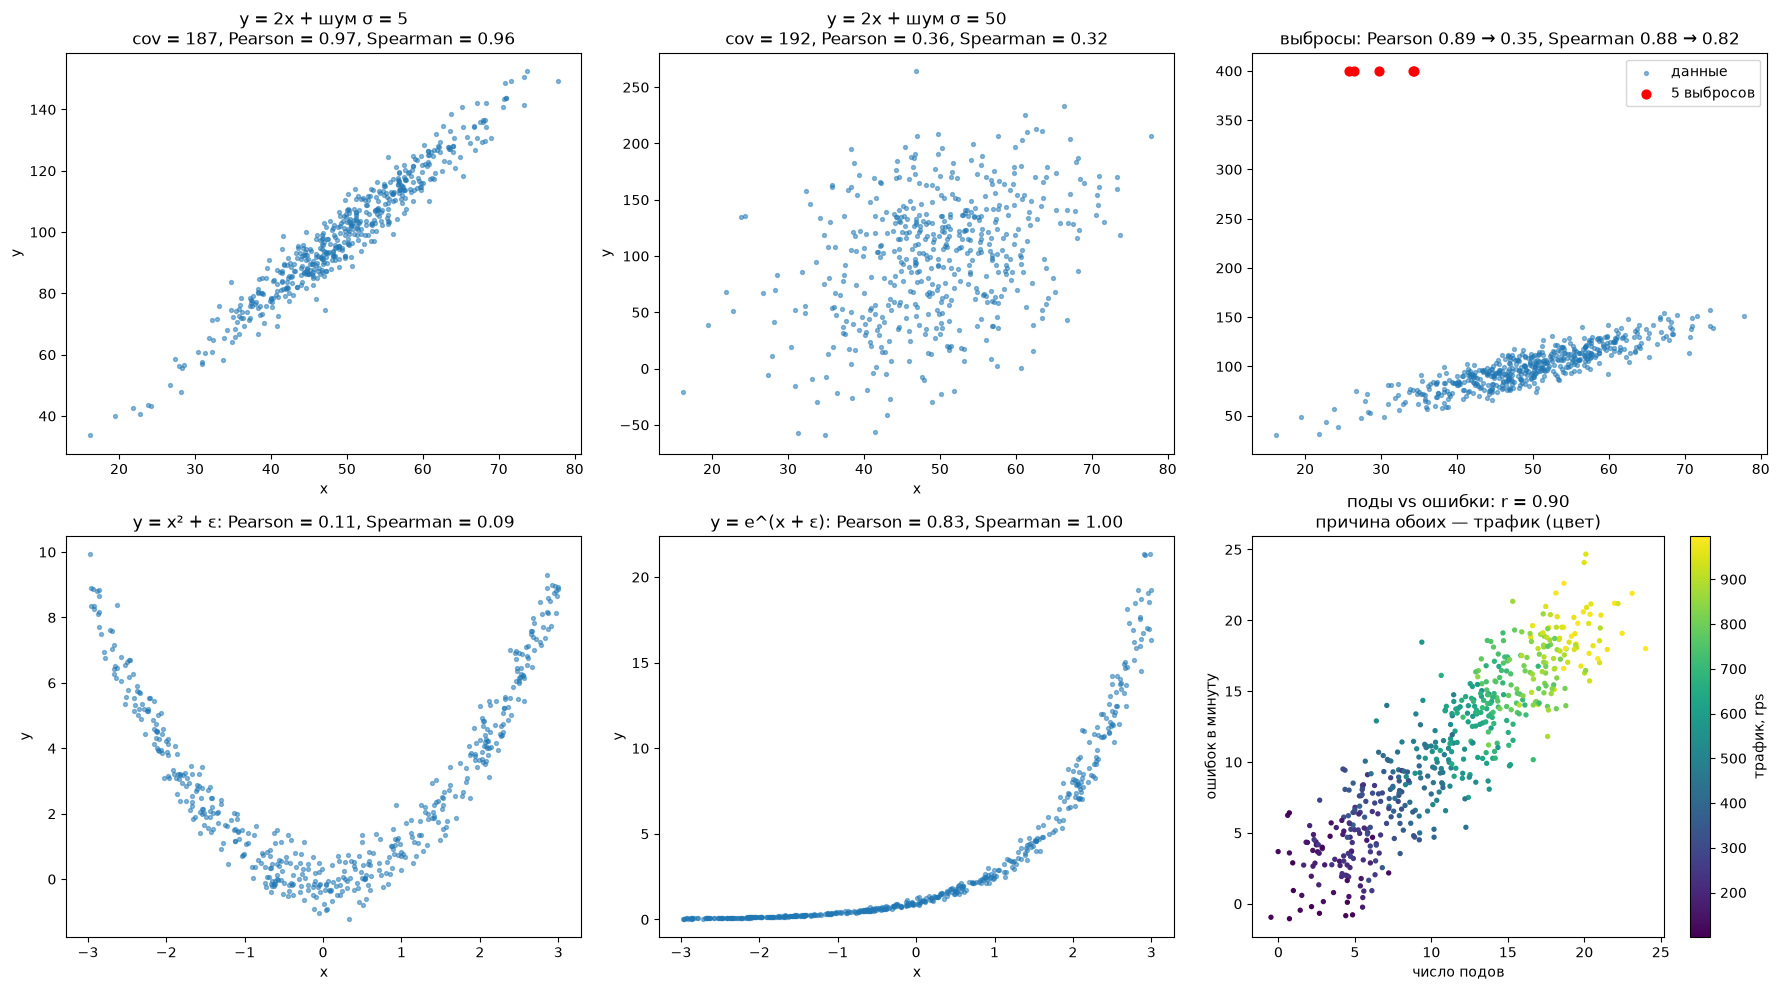

In [7]:
# 1) линейная связь + растущий шум
x = rng.normal(50, 10, 500)
noise_levels = (0, 5, 20, 50, 100)
ys = {s: 2 * x + rng.normal(0, s, len(x)) for s in noise_levels}
noise_tab = pd.DataFrame({f"шум σ = {s}": corrs(x, y) for s, y in ys.items()}).T
noise_tab["Pearson теория"] = [2 * 10 / np.sqrt(4 * 100 + s**2) for s in noise_levels]
print(noise_tab.round(3), "\n")

# 2) выбросы
y10 = 2 * x + rng.normal(0, 10, len(x))
x_out = np.concatenate([x, rng.uniform(25, 35, 5)])        # 5 точек с маленьким x ...
y_out = np.concatenate([y10, np.full(5, 400.0)])           # ... и огромным y
out_tab = pd.DataFrame({"без выбросов": corrs(x, y10), "+5 выбросов": corrs(x_out, y_out)}).T
print(out_tab.round(3), "\n")

# 3) нелинейные связи
u = rng.uniform(-3, 3, 500)
y_par = u**2 + rng.normal(0, 0.5, len(u))
y_exp = np.exp(u + rng.normal(0, 0.1, len(u)))
nl_tab = pd.DataFrame({"y = x² + ε (не монотонная)": corrs(u, y_par),
                       "y = e^(x + ε) (монотонная)": corrs(u, y_exp)}).T
print(nl_tab.round(3), "\n")

# 4) корреляция без причинности: трафик → поды, трафик → ошибки
traffic = rng.uniform(100, 1000, 500)
pods = traffic / 50 + rng.normal(0, 1.5, len(traffic))
errors = 0.02 * traffic + rng.normal(0, 2, len(traffic))
mask = (traffic > 500) & (traffic < 550)                   # фиксируем трафик
print(f"поды vs ошибки, весь трафик: r = {stats.pearsonr(pods, errors).statistic:.2f}")
print(f"поды vs ошибки, трафик 500–550 rps: r = {stats.pearsonr(pods[mask], errors[mask]).statistic:.2f} (n = {mask.sum()})")

# графики
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, s in zip(axes[0, :2], (5, 50)):
    c = corrs(x, ys[s])
    ax.scatter(x, ys[s], s=8, alpha=0.5)
    ax.set_title(f"y = 2x + шум σ = {s}\ncov = {c['cov']:.0f}, Pearson = {c['Pearson']:.2f}, Spearman = {c['Spearman']:.2f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
c0, c1 = corrs(x, y10), corrs(x_out, y_out)
axes[0, 2].scatter(x, y10, s=8, alpha=0.5, label="данные")
axes[0, 2].scatter(x_out[-5:], y_out[-5:], s=40, color="red", label="5 выбросов")
axes[0, 2].set_title(f"выбросы: Pearson {c0['Pearson']:.2f} → {c1['Pearson']:.2f}, "
                     f"Spearman {c0['Spearman']:.2f} → {c1['Spearman']:.2f}")
axes[0, 2].legend()
for ax, (yy, name) in zip(axes[1, :2], [(y_par, "y = x² + ε"), (y_exp, "y = e^(x + ε)")]):
    c = corrs(u, yy)
    ax.scatter(u, yy, s=8, alpha=0.5)
    ax.set_title(f"{name}: Pearson = {c['Pearson']:.2f}, Spearman = {c['Spearman']:.2f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
sc = axes[1, 2].scatter(pods, errors, c=traffic, s=8, cmap="viridis")
plt.colorbar(sc, ax=axes[1, 2], label="трафик, rps")
axes[1, 2].set_title(f"поды vs ошибки: r = {stats.pearsonr(pods, errors).statistic:.2f}\nпричина обоих — трафик (цвет)")
axes[1, 2].set_xlabel("число подов"); axes[1, 2].set_ylabel("ошибок в минуту")
plt.tight_layout(); plt.show()

### 6.1 Ожидание

_Что ожидаю получить до расчётов:_

...

In [ ]:
# задание 6

### 6.2 Вывод

...

## 7. Дисперсионный анализ

Три группы с разными средними и одинаковой дисперсией.

- сформулируй гипотезы однофакторного ANOVA
- проведи ANOVA и интерпретируй результат
- проверь предпосылки нормальности и равенства дисперсий
- измени данные так, чтобы предпосылки нарушались, и сравни результат с критерием Краскела — Уоллиса
- проведи post-hoc сравнения между группами
- объясни, почему нельзя заменять ANOVA множеством независимых t-тестов

Три версии сервиса, время ответа, n = 50 в каждой, σ = 20 у всех:
  v1 ~ N(200, 20),   v2 ~ N(195, 20),   v3 ~ N(185, 20)
H0: μ1 = μ2 = μ3 (версии не отличаются)
H1: хотя бы одно среднее отличается
F = разброс между средними групп / разброс внутри групп; при H0 F ≈ 1

Ожидаю:
  предпосылки выполнены: Shapiro p > 0.05 в каждой группе, Levene p > 0.05
  ANOVA: p < 0.05 (v3 быстрее на 10–15 мс, SE разницы = 20·√(2/50) = 4 мс)
  Тьюки: v1–v3 различаются, v2–v3 — вероятно, v1–v2 (5 мс) — скорее нет

Нарушаю предпосылки: добавляю 3 таймаута (1500–2000 мс) в v3
  ANOVA «ослепнет»: выбросы раздуют разброс внутри группы → p > 0.05
  Kruskal — Уоллис работает по рангам → всё ещё увидит, что v3 быстрее

5 одинаковых групп → 10 парных t-тестов: хоть одна ложная тревога в ~30–40% экспериментов,
  у ANOVA — около 5%, у t-тестов с Бонферрони — не больше 5%

### 7.1 Ожидание

_Что ожидаю получить до расчётов:_

...

       n  среднее     std  Shapiro p
v1  50.0  194.147  17.881      0.940
v2  50.0  193.936  17.146      0.344
v3  50.0  182.479  18.314      0.972
Levene p = 0.936, std max/min = 1.1

ANOVA: F = 7.04, p = 0.0012
Kruskal–Wallis: H = 13.70, p = 0.0011

post-hoc Тьюки:
         разница  p (Тьюки)       95% ДИ
пара                                    
v1 − v2    0.211      0.998  [-8.2; 8.6]
v1 − v3   11.668      0.004  [3.2; 20.1]
v2 − v3   11.457      0.004  [3.0; 19.9] 

       n  среднее      std  Shapiro p
v1  50.0  194.147   17.881      0.940
v2  50.0  193.936   17.146      0.344
v3  53.0  270.263  365.590      0.000
Levene p = 0.057, std max/min = 21.3

ANOVA: F = 2.16, p = 0.1186
Kruskal–Wallis: H = 8.91, p = 0.0116

post-hoc для нарушенных данных: Манн — Уитни + Бонферрони
              p  p × число пар (Бонферрони)
пара                                       
v1 vs v2  0.942                       1.000
v1 vs v3  0.013                       0.040
v2 vs v3  0.008                    

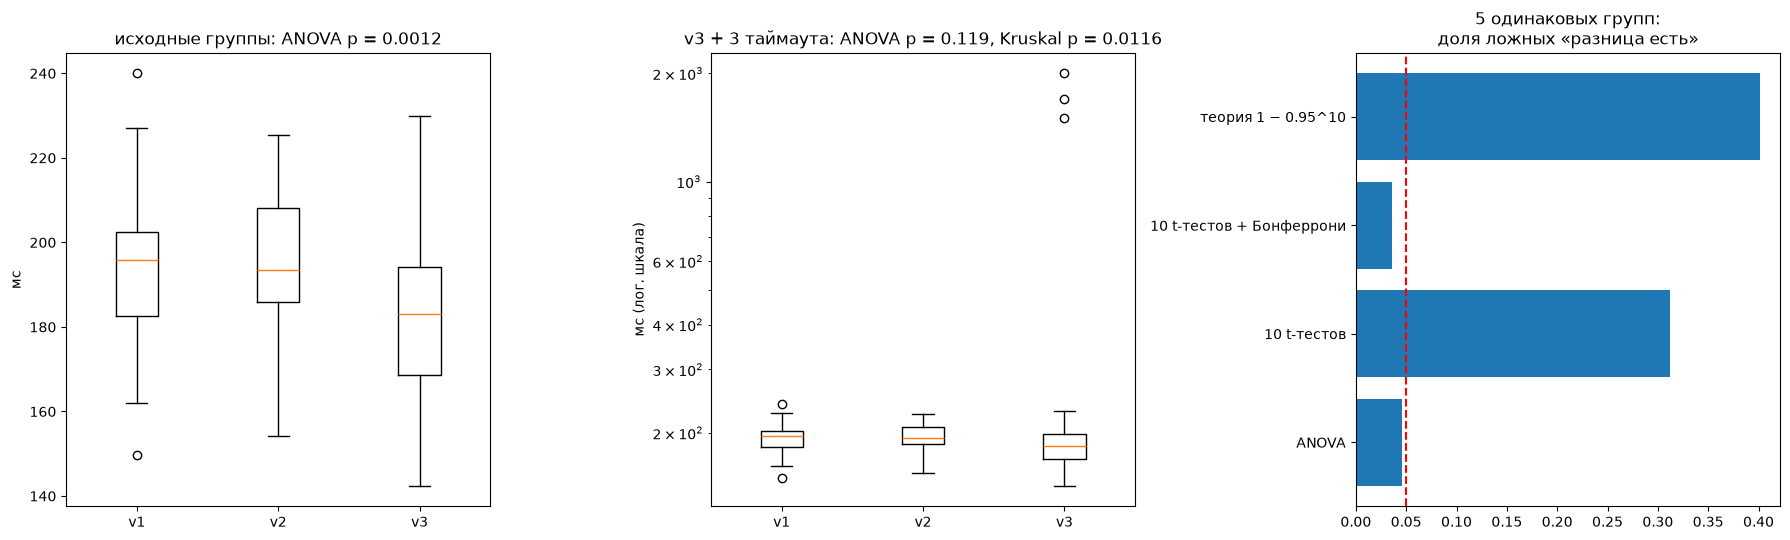

In [11]:
# задание 7
rng = np.random.default_rng(7)     # свой seed: результат не зависит от перезапусков других ячеек

# 1) три группы, проверка предпосылок
groups = {"v1": rng.normal(200, 20, 50), "v2": rng.normal(195, 20, 50), "v3": rng.normal(185, 20, 50)}
desc, lev_p = check_assumptions(groups)
print(desc.round(3)); print(f"Levene p = {lev_p:.3f}, std max/min = {desc['std'].max() / desc['std'].min():.1f}\n")

# 2) ANOVA и Kruskal — Уоллис
anova = stats.f_oneway(*groups.values())
kw = stats.kruskal(*groups.values())
print(f"ANOVA: F = {anova.statistic:.2f}, p = {anova.pvalue:.4f}")
print(f"Kruskal–Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.4f}\n")

# 3) post-hoc Тьюки: какие пары отличаются
tk = stats.tukey_hsd(*groups.values())
ci = tk.confidence_interval()
names = list(groups)
rows = []
for i, j in combinations(range(3), 2):
    rows.append({"пара": f"{names[i]} − {names[j]}", "разница": groups[names[i]].mean() - groups[names[j]].mean(),
                 "p (Тьюки)": tk.pvalue[i, j], "95% ДИ": f"[{ci.low[i, j]:.1f}; {ci.high[i, j]:.1f}]"})
print("post-hoc Тьюки:"); print(pd.DataFrame(rows).set_index("пара").round(4), "\n")

# 4) нарушаем предпосылки: 3 таймаута в v3
bad = dict(groups)
bad["v3"] = np.concatenate([groups["v3"], [1500, 1700, 2000]])
desc_b, lev_b = check_assumptions(bad)
print(desc_b.round(3)); print(f"Levene p = {lev_b:.3f}, std max/min = {desc_b['std'].max() / desc_b['std'].min():.1f}\n")
anova_b, kw_b = stats.f_oneway(*bad.values()), stats.kruskal(*bad.values())
print(f"ANOVA: F = {anova_b.statistic:.2f}, p = {anova_b.pvalue:.4f}")
print(f"Kruskal–Wallis: H = {kw_b.statistic:.2f}, p = {kw_b.pvalue:.4f}\n")
print("post-hoc для нарушенных данных: Манн — Уитни + Бонферрони")
print(pairwise_mw(bad).round(4), "\n")

# 5) почему не куча t-тестов: 5 ОДИНАКОВЫХ групп, 2000 экспериментов
reps, k, n = 2000, 5, 30
data = rng.normal(200, 20, (reps, k, n))
p_anova = stats.f_oneway(*[data[:, i, :] for i in range(k)], axis=1).pvalue
pair_p = np.array([stats.ttest_ind(data[:, i, :], data[:, j, :], axis=1).pvalue
                   for i, j in combinations(range(k), 2)])
m = len(pair_p)                                   # 10 пар
fw = pd.Series({
    "ANOVA": np.mean(p_anova < 0.05),
    f"{m} t-тестов": np.mean((pair_p < 0.05).any(axis=0)),           # хоть один p < 0.05
    f"{m} t-тестов + Бонферрони": np.mean((pair_p < 0.05 / m).any(axis=0)),
    f"теория 1 − 0.95^{m}": 1 - 0.95**m,
})
print(f"5 одинаковых групп, {reps} экспериментов — доля ложных «разница есть»:"); print(fw.round(3))

# графики
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].boxplot(list(groups.values()), tick_labels=names)
axes[0].set_title(f"исходные группы: ANOVA p = {anova.pvalue:.4f}"); axes[0].set_ylabel("мс")
axes[1].boxplot(list(bad.values()), tick_labels=names)
axes[1].set_yscale("log")
axes[1].set_title(f"v3 + 3 таймаута: ANOVA p = {anova_b.pvalue:.3f}, Kruskal p = {kw_b.pvalue:.4f}")
axes[1].set_ylabel("мс (лог. шкала)")
axes[2].barh(fw.index, fw.values)
axes[2].axvline(0.05, color="red", ls="--")
axes[2].set_title("5 одинаковых групп:\nдоля ложных «разница есть»")
plt.tight_layout(); plt.show()

### 7.2 Вывод

...

## 8. Итоговая практика: статистический анализ данных

Реальный табличный датасет минимум из 500 строк.

- опиши генеральную совокупность, выборку и смысл признаков
- исследуй пропуски, выбросы и распределения
- рассчитай описательные статистики
- сформулируй минимум три проверяемые гипотезы
- выбери для каждой гипотезы подходящий статистический критерий и обоснуй выбор
- построй доверительные интервалы и оцени размер эффекта
- исследуй связи между признаками
- добавь минимум пять информативных визуализаций
- сформулируй выводы простым языком, не ограничиваясь p-value

### 8.1 Ожидание

_Что ожидаю получить до расчётов:_

...

Генеральная совокупность: все клиенты телеком-компании (текущие и будущие).
Выборка: 7043 клиента за один квартал → выводы верны для похожих клиентов и периода.

Признаки:
  tenure          — сколько месяцев клиент с компанией
  MonthlyCharges  — ежемесячный платёж, $
  TotalCharges    — сколько всего заплатил, $
  Contract        — контракт: помесячный / 1 год / 2 года
  PaymentMethod   — способ оплаты: автоплатёж с банка или карты / электронный чек / чек почтой
  InternetService — интернет: DSL / оптоволокно / нет
  SeniorCitizen   — пенсионер (1) или нет (0)
  Churn           — ушёл ли клиент в последний месяц (целевой признак)

Гипотезы и выбор критерия:
H1: ушедшие клиенты платили в месяц больше оставшихся.
    Числовой признак, 2 группы → t-тест Уэлча: дисперсии разные, n в тысячах,
    поэтому по ЦПТ средние нормальны, даже если сами данные нет.
    Проверка устойчивости — Манн — Уитни. Эффект: ДИ разницы и Cohen's d.
H2: доля ухода зависит от типа контракта: на помесячном уходят чаще.
    Два категориальных признака → χ² независимости. Эффект: Cramér's V и ДИ долей.
H3: стаж клиента различается по способу оплаты: с автоплатежом остаются дольше.
    Числовой признак, 4 группы, tenure далёк от нормального → Kruskal — Уоллис вместо ANOVA,
    post-hoc Манн — Уитни с Бонферрони. Эффект: ε² и разница медиан.
Нормальность проверяю по графикам, а не Шапиро: на n в тысячи он отвергает всегда (задание 4).

(7043, 21)
   tenure  MonthlyCharges TotalCharges        Contract              PaymentMethod Churn
0       1           29.85        29.85  Month-to-month           Electronic check    No
1      34           56.95       1889.5        One year               Mailed check    No
2       2           53.85       108.15  Month-to-month               Mailed check   Yes
3      45           42.30      1840.75        One year  Bank transfer (automatic)    No
4       2           70.70       151.65  Month-to-month           Electronic check   Yes
пропуски: {'TotalCharges': 11}
     tenure  MonthlyCharges  TotalCharges
488       0           52.55           NaN
753       0           20.25           NaN
936       0           80.85           NaN
дубликатов customerID: 0
асимметрия: {'tenure': 0.24, 'MonthlyCharges': -0.22, 'TotalCharges': 0.96}


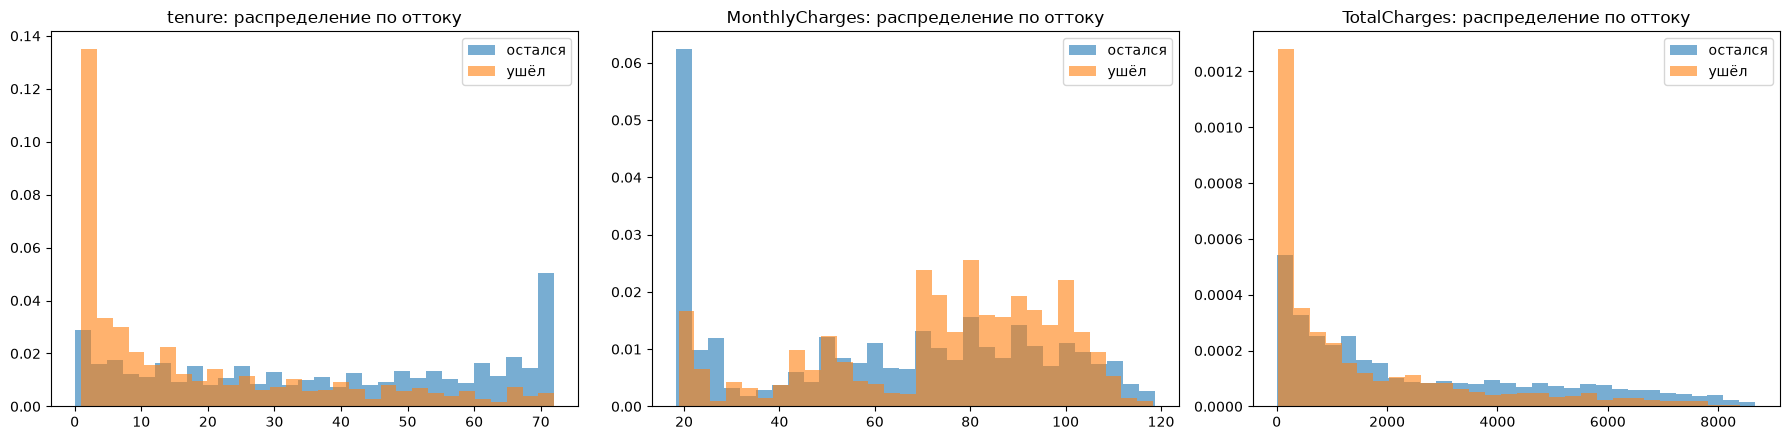

                     tenure  MonthlyCharges  TotalCharges
среднее                32.4            64.8       2,279.7
медиана                29.0            70.3       1,394.5
мода (округл.)          1.0            20.0          20.0
дисперсия             603.2           905.4   5,138,357.2
std                    24.6            30.1       2,266.8
Q1                      9.0            35.5         398.6
Q3                     55.0            89.8       3,786.6
IQR                    46.0            54.3       3,388.0
выбросов по 1.5·IQR     0.0             0.0           0.0 

доля ушедших: 0.265, 95% ДИ [0.255; 0.276]

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4       1,679.5
Yes      10.0            79.7         703.5 

            доля ухода     n
контракт                    
1 год            0.113  1473
2 года           0.028  1695
помесячный       0.427  3875 

              доля ухода     n
оплата            

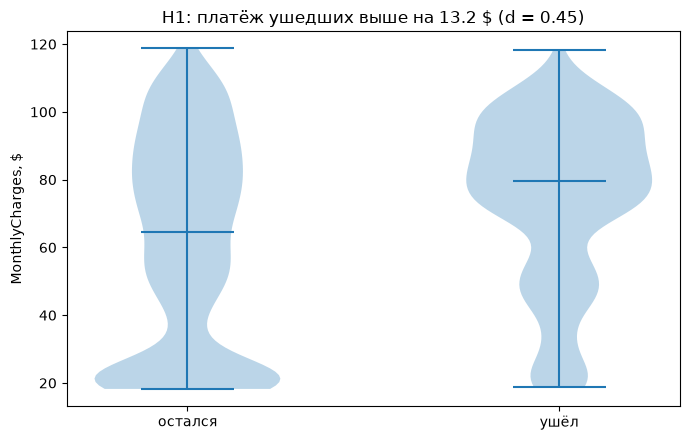

In [16]:
# задание 8
from pathlib import Path

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
path = Path("data/telco_churn.csv")
if not path.exists():                          # файла нет → скачать один раз и сохранить рядом с ноутбуком
    path.parent.mkdir(exist_ok=True)
    pd.read_csv(URL).to_csv(path, index=False)
df = pd.read_csv(path)
print(df.shape)
print(df[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "PaymentMethod", "Churn"]].head().to_string())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # пустые строки " " → NaN
print("пропуски:", df.isna().sum()[lambda s: s > 0].to_dict())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head(3).to_string())
df["TotalCharges"] = df["TotalCharges"].fillna(0)        # tenure = 0: новый клиент, ещё ничего не заплатил
print("дубликатов customerID:", df["customerID"].duplicated().sum())

df["churn"] = (df["Churn"] == "Yes").astype(int)         # 1 — ушёл, 0 — остался
df["контракт"] = df["Contract"].map({"Month-to-month": "помесячный", "One year": "1 год", "Two year": "2 года"})
df["оплата"] = df["PaymentMethod"].map({"Bank transfer (automatic)": "банк (авто)", "Credit card (automatic)": "карта (авто)",
                                        "Electronic check": "эл. чек", "Mailed check": "чек почтой"})
num = ["tenure", "MonthlyCharges", "TotalCharges"]
print("асимметрия:", df[num].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, num):
    for val, name in [(0, "остался"), (1, "ушёл")]:
        ax.hist(df.loc[df["churn"] == val, c], bins=30, alpha=0.6, density=True, label=name)
    ax.set_title(f"{c}: распределение по оттоку"); ax.legend()
plt.tight_layout(); plt.show()
fmt = lambda v: f"{v:,.1f}"
print(pd.DataFrame({c: describe(df[c].to_numpy()) for c in num}).to_string(float_format=fmt), "\n")
p, lo, hi = prop_ci(df["churn"].sum(), len(df))
print(f"доля ушедших: {p:.3f}, 95% ДИ [{lo:.3f}; {hi:.3f}]\n")
print(df.groupby("Churn")[num].median().to_string(float_format=fmt), "\n")
for c in ["контракт", "оплата", "InternetService", "SeniorCitizen"]:
    print(df.groupby(c)["churn"].agg(["mean", "size"]).set_axis(["доля ухода", "n"], axis=1).round(3), "\n")
    stay = df.loc[df["churn"] == 0, "MonthlyCharges"].to_numpy()
left = df.loc[df["churn"] == 1, "MonthlyCharges"].to_numpy()
print(f"Levene p = {stats.levene(stay, left).pvalue:.1e} → дисперсии разные → Уэлч")
w = stats.ttest_ind(left, stay, equal_var=False)
ci = w.confidence_interval()
mw = stats.mannwhitneyu(left, stay)
print(f"средние: ушли {left.mean():.2f} $, остались {stay.mean():.2f} $, разница {left.mean() - stay.mean():.2f} $")
print(f"Уэлч: t = {w.statistic:.2f}, p = {w.pvalue:.1e}, 95% ДИ разницы [{ci.low:.2f}; {ci.high:.2f}] $")
print(f"Манн — Уитни: p = {mw.pvalue:.1e}; медианы {np.median(left):.2f} vs {np.median(stay):.2f} $")
print(f"Cohen's d = {cohens_d(stay, left):.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.violinplot([stay, left], showmedians=True)
ax.set_xticks([1, 2], ["остался", "ушёл"]); ax.set_ylabel("MonthlyCharges, $")
ax.set_title(f"H1: платёж ушедших выше на {left.mean() - stay.mean():.1f} $ (d = {cohens_d(stay, left):.2f})")
plt.tight_layout(); plt.show()

Churn         No   Yes
контракт              
помесячный  2220  1655
1 год       1307   166
2 года      1647    48 

χ² = 1184.6, степеней свободы = 2, p = 5.9e-258, Cramér's V = 0.41

            доля ухода  ДИ низ  ДИ верх
помесячный       0.427   0.412    0.443
1 год            0.113   0.097    0.129
2 года           0.028   0.020    0.036
помесячные уходят в 15 раз чаще двухлетних


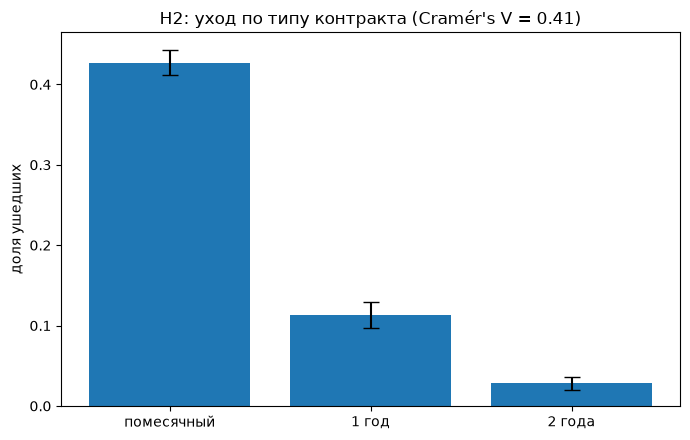

In [17]:
order = ["помесячный", "1 год", "2 года"]
table = pd.crosstab(df["контракт"], df["Churn"]).loc[order]      # таблица сопряжённости
print(table, "\n")
chi = stats.chi2_contingency(table)
print(f"χ² = {chi.statistic:.1f}, степеней свободы = {chi.dof}, p = {chi.pvalue:.1e}, Cramér's V = {cramers_v(table):.2f}\n")
rows = {}
for c in order:
    g = df[df["контракт"] == c]
    rows[c] = dict(zip(["доля ухода", "ДИ низ", "ДИ верх"], prop_ci(g["churn"].sum(), len(g))))
rates = pd.DataFrame(rows).T
print(rates.round(3))
print(f"помесячные уходят в {rates.loc['помесячный', 'доля ухода'] / rates.loc['2 года', 'доля ухода']:.0f} раз чаще двухлетних")

fig, ax = plt.subplots(figsize=(7, 4.5))
err = [rates["доля ухода"] - rates["ДИ низ"], rates["ДИ верх"] - rates["доля ухода"]]
ax.bar(rates.index, rates["доля ухода"], yerr=err, capsize=6)
ax.set_ylabel("доля ушедших"); ax.set_title(f"H2: уход по типу контракта (Cramér's V = {cramers_v(table):.2f})")
plt.tight_layout(); plt.show()

                   n  медиана  среднее
банк (авто)   1544.0     48.0     43.7
карта (авто)  1522.0     47.0     43.3
чек почтой    1612.0     15.0     21.8
эл. чек       2365.0     18.0     25.2 

Kruskal — Уоллис: H = 1158.5, p = 7.2e-251, ε² = 0.16

                                   p  p × число пар (Бонферрони)
пара                                                            
банк (авто) vs карта (авто)  6.6e-01                     1.0e+00
банк (авто) vs чек почтой   1.8e-139                    1.1e-138
банк (авто) vs эл. чек      1.0e-120                    6.3e-120
карта (авто) vs чек почтой  1.5e-134                    8.9e-134
карта (авто) vs эл. чек     1.6e-115                    9.9e-115
чек почтой vs эл. чек        1.4e-06                     8.5e-06


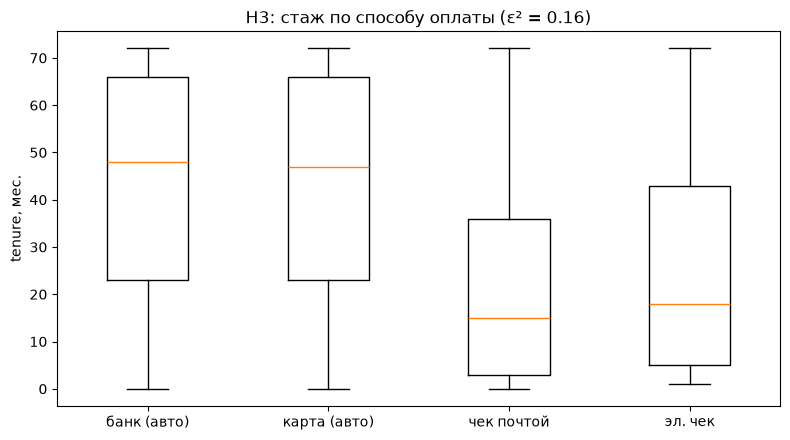

In [18]:
groups = {m: g["tenure"].to_numpy() for m, g in df.groupby("оплата")}
print(pd.DataFrame({m: {"n": len(g), "медиана": np.median(g), "среднее": g.mean()} for m, g in groups.items()}).T.round(1), "\n")
kw = stats.kruskal(*groups.values())
eps2 = kw.statistic / (len(df) - 1)
print(f"Kruskal — Уоллис: H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, ε² = {eps2:.2f}\n")
print(pairwise_mw(groups).to_string(float_format=lambda v: f"{v:.1e}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(groups.values()), tick_labels=list(groups))
ax.set_ylabel("tenure, мес."); ax.set_title(f"H3: стаж по способу оплаты (ε² = {eps2:.2f})")
plt.tight_layout(); plt.show()

                tenure  MonthlyCharges  TotalCharges  SeniorCitizen  churn
tenure            1.00            0.28          0.89           0.02  -0.37
MonthlyCharges    0.28            1.00          0.64           0.22   0.18
TotalCharges      0.89            0.64          1.00           0.11  -0.23
SeniorCitizen     0.02            0.22          0.11           1.00   0.15
churn            -0.37            0.18         -0.23           0.15   1.00 

TotalCharges vs tenure × MonthlyCharges: r = 1.000


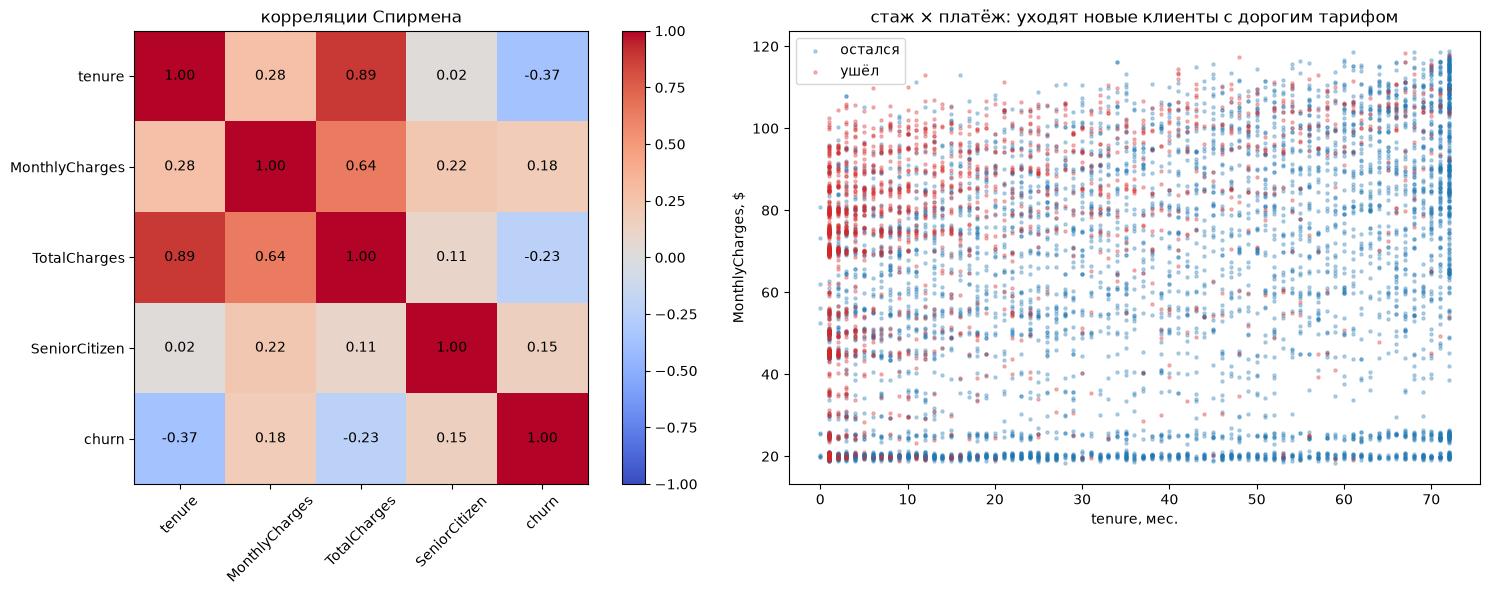

In [19]:
cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn"]
corr = df[cols].corr(method="spearman")
print(corr.round(2), "\n")
print(f"TotalCharges vs tenure × MonthlyCharges: r = {stats.pearsonr(df['TotalCharges'], df['tenure'] * df['MonthlyCharges']).statistic:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
im = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(cols)), cols, rotation=45); axes[0].set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        axes[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, ax=axes[0]); axes[0].set_title("корреляции Спирмена")
for val, name, color in [(0, "остался", "tab:blue"), (1, "ушёл", "tab:red")]:
    part = df[df["churn"] == val]
    axes[1].scatter(part["tenure"], part["MonthlyCharges"], s=5, alpha=0.3, color=color, label=name)
axes[1].set_xlabel("tenure, мес."); axes[1].set_ylabel("MonthlyCharges, $"); axes[1].legend()
axes[1].set_title("стаж × платёж: уходят новые клиенты с дорогим тарифом")
plt.tight_layout(); plt.show()

### 8.2 Вывод

...

## 9. Где это в машинном обучении

_Где в ML используются описательная статистика, доверительные интервалы, проверка гипотез и корреляция — с привязкой к заданиям выше._

...

Описательная статистика и выбросы (1, 8): первый шаг любого ML-проекта — посмотреть на данные. В Telco так нашлись 11 пропусков (новые клиенты) и дублирующий признак TotalCharges. Выбросы раздувают среднее и MSE так же, как std в задании 1. Поэтому используют медиану, MAE и масштабирование через медиану и IQR (RobustScaler).
Выборка и стандартная ошибка (2): тестовый набор — это выборка. Метрика на нём — оценка с погрешностью около 1/√n, поэтому на маленьком тесте метрика скачет.
Доверительные интервалы и bootstrap (3): у метрики модели всегда стоит указывать ДИ. Bootstrap по тестовым примерам даёт ДИ для чего угодно: F1, ROC-AUC, оценок LLM-судьи.
Распределения (4):
на Бернулли построен log-loss в бинарной классификации, например в предсказании оттока;
Пуассон описывает счётчики: заказы, инциденты;
стандартизация — это StandardScaler перед обучением.
Проверка гипотез и ANOVA (5, 7):
это A/B-тесты новых моделей и промптов;
практическая значимость важнее p-value;
при сравнении многих вариантов нужна поправка на множественность. Иначе «лучший из 20 промптов» окажется просто везением.
Корреляция (6, 8):
помогает отбирать признаки, искать утечки и дубли (TotalCharges ≈ tenure × MonthlyCharges);
но корреляция ≠ причинность. Модель оттока предскажет, кто уйдёт, но не скажет, что поможет его удержать. Для такого решения нужен A/B-тест.
Несбалансированные классы (8): в Telco модель «все остаются» уже даёт 73.5% accuracy. Поэтому качество смотрят по precision и recall — та же логика базовой частоты, что в Байесе из теорвера.

## Перед сдачей

- [ ] `Restart & Run All` проходит без ошибок
- [ ] у каждого задания есть: ожидание → расчёт → график → вывод
- [ ] выводы написаны своими словами